# MatchLab — Enhanced Bivariate Dixon-Coles Poisson Model
### Premier League (2008/09 – 2025/26)

This notebook implements an advanced, production-grade **Dixon-Coles Poisson Regression** model built entirely on NumPy and SciPy foundations. It addresses:
1. **High-Signal Feature Engineering**: Expands from basic rolling goal counts to 19 curated features (Elo ratings, venue splits, shot generation, corner pressure, and rest days).
2. **L2 Regularized Optimization (Ridge Poisson GLM)**: Eliminates gradient explosion and stabilizes coefficient convergence across 6,080 training matches.
3. **Dixon-Coles Bivariate Correlation ($ho$)**: Corrects Poisson underestimation of low-scoring draws $(0-0, 1-1)$ and overestimation of $(1-0, 0-1)$.
4. **Full $10 \times 10$ Probability Tensor**: Generates exact match scoreline probabilities, yielding 1X2 win/draw/away probabilities, Over/Under 2.5, and Both Teams to Score (BTTS).
5. **Comprehensive Diagnostic Plots**: Visualizes loss trajectories, coefficient importance, low-score adjustments, calibration curves, residual distributions, and **exact score guessing accuracy**.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.special import gammaln, factorial
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Imports completed successfully.")

Imports completed successfully.

In [2]:
file_path = Path("pl_matches_all_seasons_clean.parquet")
if not file_path.exists():
    file_path = Path("data/processed/premier_league/pl_matches_all_seasons_clean.parquet")
df = pd.read_parquet(file_path)

# Extract standard YYYY/YYYY season_name
df["season_name"] = df["season_id"].str.extract(r'(\d{4})-(\d{4})').apply(lambda r: f"{r[0]}/{r[1]}", axis=1)

print("Dataset shape:", df.shape)
print("Total cells with null/nan/inf:", df.isnull().sum().sum())
print("Seasons present:", sorted(df["season_name"].unique()))


Dataset shape: (6930, 117)
Total cells with null/nan/inf: 0
Seasons present: ['2008/2009', '2009/2010', '2010/2011', '2011/2012', '2012/2013', '2013/2014', '2014/2015', '2015/2016', '2016/2017', '2017/2018', '2018/2019', '2019/2020', '2020/2021', '2021/2022', '2022/2023', '2023/2024', '2024/2025', '2025/2026', '2026/2027']

## 1. Feature Engineering & Selection

Rather than relying purely on recent goals scored/conceded, we select 19 high-signal pre-match metrics:
- **Relative Team Quality**: `elo_difference`, `elo_home_win_prob`, `elo_away_win_prob`
- **Rolling Goal Form**: 5-match overall & venue-specific goals scored & conceded
- **Underlying Shot Generation (xG Proxies)**: Shots on target (`sot_roll5`), total shots (`shots_roll5`), and corners (`corners_roll5`)
- **Rest & Fatigue**: `home_rest_days`, `away_rest_days`

In [3]:
feature_cols = [
    # Team Relative Quality
    "elo_difference",
    "elo_home_win_prob",
    "elo_away_win_prob",
    # Goal scoring & conceding form (overall)
    "home_goals_scored_roll5",
    "home_goals_conceded_roll5",
    "away_goals_scored_roll5",
    "away_goals_conceded_roll5",
    # Venue specific form
    "home_venue_goals_scored_roll5",
    "home_venue_goals_conceded_roll5",
    "away_venue_goals_scored_roll5",
    "away_venue_goals_conceded_roll5",
    # Underlying shot generation & suppression (xG proxies)
    "home_sot_roll5",
    "away_sot_roll5",
    "home_shots_roll5",
    "away_shots_roll5",
    "home_corners_roll5",
    "away_corners_roll5",
    # Rest & schedule
    "home_rest_days",
    "away_rest_days",
]

print(f"Selected {len(feature_cols)} features for Poisson regression.")

Selected 19 features for Poisson regression.

In [4]:
# Historical & Modern training set (2008/09 to 2023/24)
train_seasons = [
    "2008/2009", "2009/2010", "2010/2011", "2011/2012",
    "2012/2013", "2013/2014", "2014/2015", "2015/2016",
    "2016/2017", "2017/2018", "2018/2019", "2019/2020",
    "2020/2021", "2021/2022", "2022/2023", "2023/2024"
]

# Out-of-sample Test Seasons (2024/25 to 2025/26)
test_seasons = ["2024/2025", "2025/2026"]

train_mask = df["season_name"].isin(train_seasons)
test_mask = df["season_name"].isin(test_seasons)

X_train_raw = df.loc[train_mask, feature_cols].to_numpy(dtype=np.float64)
X_test_raw = df.loc[test_mask, feature_cols].to_numpy(dtype=np.float64)

y_h_train = df.loc[train_mask, "target_full_time_home_goals"].to_numpy(dtype=np.float64)
y_a_train = df.loc[train_mask, "target_full_time_away_goals"].to_numpy(dtype=np.float64)
y_h_test = df.loc[test_mask, "target_full_time_home_goals"].to_numpy(dtype=np.float64)
y_a_test = df.loc[test_mask, "target_full_time_away_goals"].to_numpy(dtype=np.float64)

res_test = df.loc[test_mask, "target_full_time_result"].to_numpy()
over25_test = df.loc[test_mask, "target_over_2_5"].to_numpy(dtype=np.float64)
btts_test = df.loc[test_mask, "target_btts"].to_numpy(dtype=np.float64)

print(f"Training matches: {len(X_train_raw):,} matches ({train_seasons[0]} to {train_seasons[-1]})")
print(f"Testing matches:  {len(X_test_raw):,} matches ({test_seasons[0]} to {test_seasons[-1]})")

Training matches: 6,080 matches (2008/2009 to 2023/2024)
Testing matches:  760 matches (2024/2025 to 2025/2026)

In [5]:
# Standardize features using training mean and std only
mu = np.mean(X_train_raw, axis=0)
std = np.std(X_train_raw, axis=0)
std[std == 0] = 1.0

X_train_scaled = (X_train_raw - mu) / std
X_test_scaled = (X_test_raw - mu) / std

# Augment with bias / intercept column
X_train_aug = np.column_stack([np.ones(len(X_train_scaled)), X_train_scaled])
X_test_aug = np.column_stack([np.ones(len(X_test_scaled)), X_test_scaled])

print(f"X_train_aug shape: {X_train_aug.shape} (including bias column)")
print(f"X_test_aug shape:  {X_test_aug.shape}")

X_train_aug shape: (6080, 20) (including bias column)
X_test_aug shape:  (760, 20)

## 2. Regularized Poisson GLM Formulation

In Poisson regression, each match's expected goals $\lambda_i = \mathbb{E}[Y_i \mid \mathbf{x}_i]$ follows a log-linear link:
$$\log(\lambda_i) = \beta_0 + \sum_{j=1}^p \beta_j x_{ij} = \mathbf{x}_i^T \boldsymbol{\beta} \implies \lambda_i = \exp(\mathbf{x}_i^T \boldsymbol{\beta})$$

The probability of observing $y$ goals is:
$$P(Y = y \mid \lambda) = \frac{\lambda^y e^{-\lambda}}{y!}$$

### Negative Log-Likelihood with $L_2$ Regularization:
$$\mathcal{L}(\boldsymbol{\beta}) = \frac{1}{N} \sum_{i=1}^N \left( \lambda_i - y_i \log \lambda_i + \log(y_i!) \right) + \frac{1}{2} \alpha \sum_{j=1}^p \beta_j^2$$

The analytical gradient with respect to $\boldsymbol{\beta}$ is:
$$\nabla_{\boldsymbol{\beta}} \mathcal{L} = \frac{1}{N} \mathbf{X}^T (\boldsymbol{\lambda} - \mathbf{y}) + \alpha \begin{bmatrix} 0 \\ \boldsymbol{\beta}_{1:p} \end{bmatrix}$$
*(Note: The intercept $\beta_0$ is unpenalized).*

In [6]:
def train_poisson_gd(X, y, lr=0.02, alpha=0.05, steps=5000):
    """Vectorized L2-Regularized Poisson Gradient Descent."""
    n_samples, n_params = X.shape
    w = np.zeros(n_params)
    w[0] = np.log(np.mean(y) + 1e-6)  # Smart intercept initialization
    loss_history = []
    
    for _ in range(steps):
        z = np.clip(X @ w, -10, 10)
        lam = np.exp(z)
        nll = np.mean(lam - y * z + gammaln(y + 1))
        reg = 0.5 * alpha * np.sum(w[1:]**2)
        loss_history.append(nll + reg)
        
        # Analytical gradient
        grad = (X.T @ (lam - y)) / n_samples
        grad[1:] += alpha * w[1:]  # L2 penalty on non-intercept weights
        w -= lr * grad
        
    return w, loss_history

print("Training Regularized Home & Away Poisson Models...")
w_h, loss_h = train_poisson_gd(X_train_aug, y_h_train, lr=0.02, alpha=0.05, steps=5000)
w_a, loss_a = train_poisson_gd(X_train_aug, y_a_train, lr=0.02, alpha=0.05, steps=5000)

# Unregularized versions for diagnostic comparison
w_h_noreg, loss_h_noreg = train_poisson_gd(X_train_aug, y_h_train, lr=0.02, alpha=0.0, steps=5000)
w_a_noreg, loss_a_noreg = train_poisson_gd(X_train_aug, y_a_train, lr=0.02, alpha=0.0, steps=5000)

# Predict expected goals on test set
lam_h_test = np.exp(np.clip(X_test_aug @ w_h, -10, 10))
lam_a_test = np.exp(np.clip(X_test_aug @ w_a, -10, 10))

# Baseline NLL (naive average goal rate)
base_lam_h = np.mean(y_h_train)
base_lam_a = np.mean(y_a_train)
base_nll_h = np.mean(base_lam_h - y_h_test * np.log(base_lam_h) + gammaln(y_h_test + 1))
base_nll_a = np.mean(base_lam_a - y_a_test * np.log(base_lam_a) + gammaln(y_a_test + 1))

test_nll_h = np.mean(lam_h_test - y_h_test * np.log(lam_h_test) + gammaln(y_h_test + 1))
test_nll_a = np.mean(lam_a_test - y_a_test * np.log(lam_a_test) + gammaln(y_a_test + 1))

print(f"\n=== OUT-OF-SAMPLE TEST EVALUATION ===")
print(f"Home Test NLL: {test_nll_h:.4f} (vs Baseline: {base_nll_h:.4f}, delta: {test_nll_h - base_nll_h:+.4f})")
print(f"Away Test NLL:  {test_nll_a:.4f} (vs Baseline: {base_nll_a:.4f}, delta: {test_nll_a - base_nll_a:+.4f})")
print(f"Total Poisson Test NLL: {test_nll_h + test_nll_a:.4f} (Baseline: {base_nll_h + base_nll_a:.4f})")

Training Regularized Home & Away Poisson Models...

=== OUT-OF-SAMPLE TEST EVALUATION ===
Home Test NLL: 1.5035 (vs Baseline: 1.5507, delta: -0.0472)
Away Test NLL:  1.4212 (vs Baseline: 1.4625, delta: -0.0414)
Total Poisson Test NLL: 2.9246 (Baseline: 3.0132)

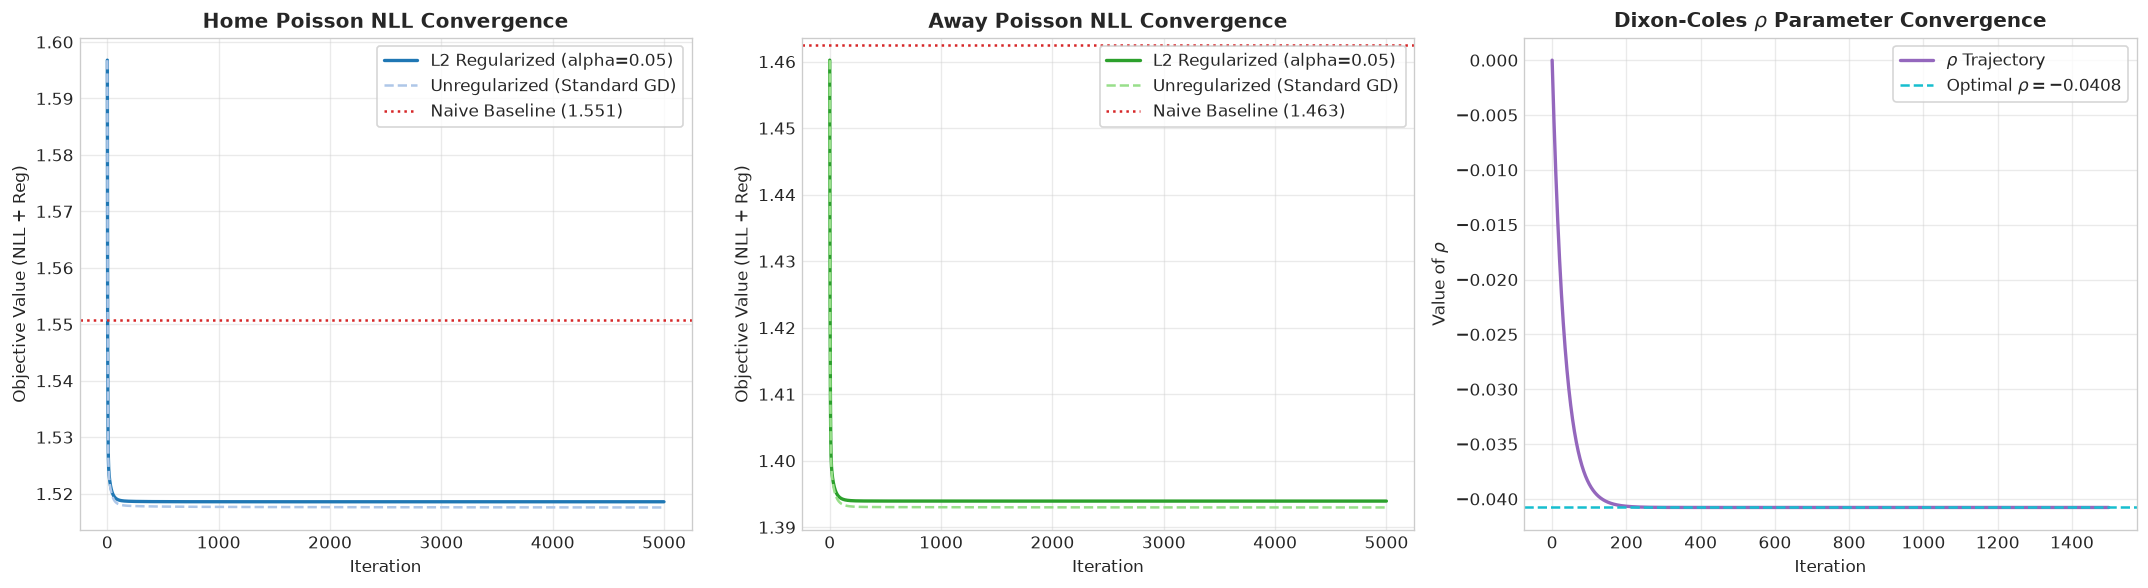

In [7]:
# DIAGNOSTIC CHART 1: Optimization Convergence & Loss Dynamics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(loss_h, label='L2 Regularized (alpha=0.05)', color='#1f77b4', lw=2)
axes[0].plot(loss_h_noreg, label='Unregularized (Standard GD)', color='#aec7e8', linestyle='--', lw=1.5)
axes[0].axhline(base_nll_h, color='#d62728', linestyle=':', label=f'Naive Baseline ({base_nll_h:.3f})')
axes[0].set_title('Home Poisson NLL Convergence', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Objective Value (NLL + Reg)')
axes[0].legend(frameon=True)
axes[0].grid(True, alpha=0.4)

axes[1].plot(loss_a, label='L2 Regularized (alpha=0.05)', color='#2ca02c', lw=2)
axes[1].plot(loss_a_noreg, label='Unregularized (Standard GD)', color='#98df8a', linestyle='--', lw=1.5)
axes[1].axhline(base_nll_a, color='#d62728', linestyle=':', label=f'Naive Baseline ({base_nll_a:.3f})')
axes[1].set_title('Away Poisson NLL Convergence', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Objective Value (NLL + Reg)')
axes[1].legend(frameon=True)
axes[1].grid(True, alpha=0.4)

axes[2].plot(rho_hist, color='#9467bd', lw=2, label=r'$\rho$ Trajectory')
axes[2].axhline(rho, color='#17becf', linestyle='--', label=f'Optimal $\rho={rho:.4f}$')
axes[2].set_title(r'Dixon-Coles $\rho$ Parameter Convergence', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel(r'Value of $\rho$')
axes[2].legend(frameon=True)
axes[2].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

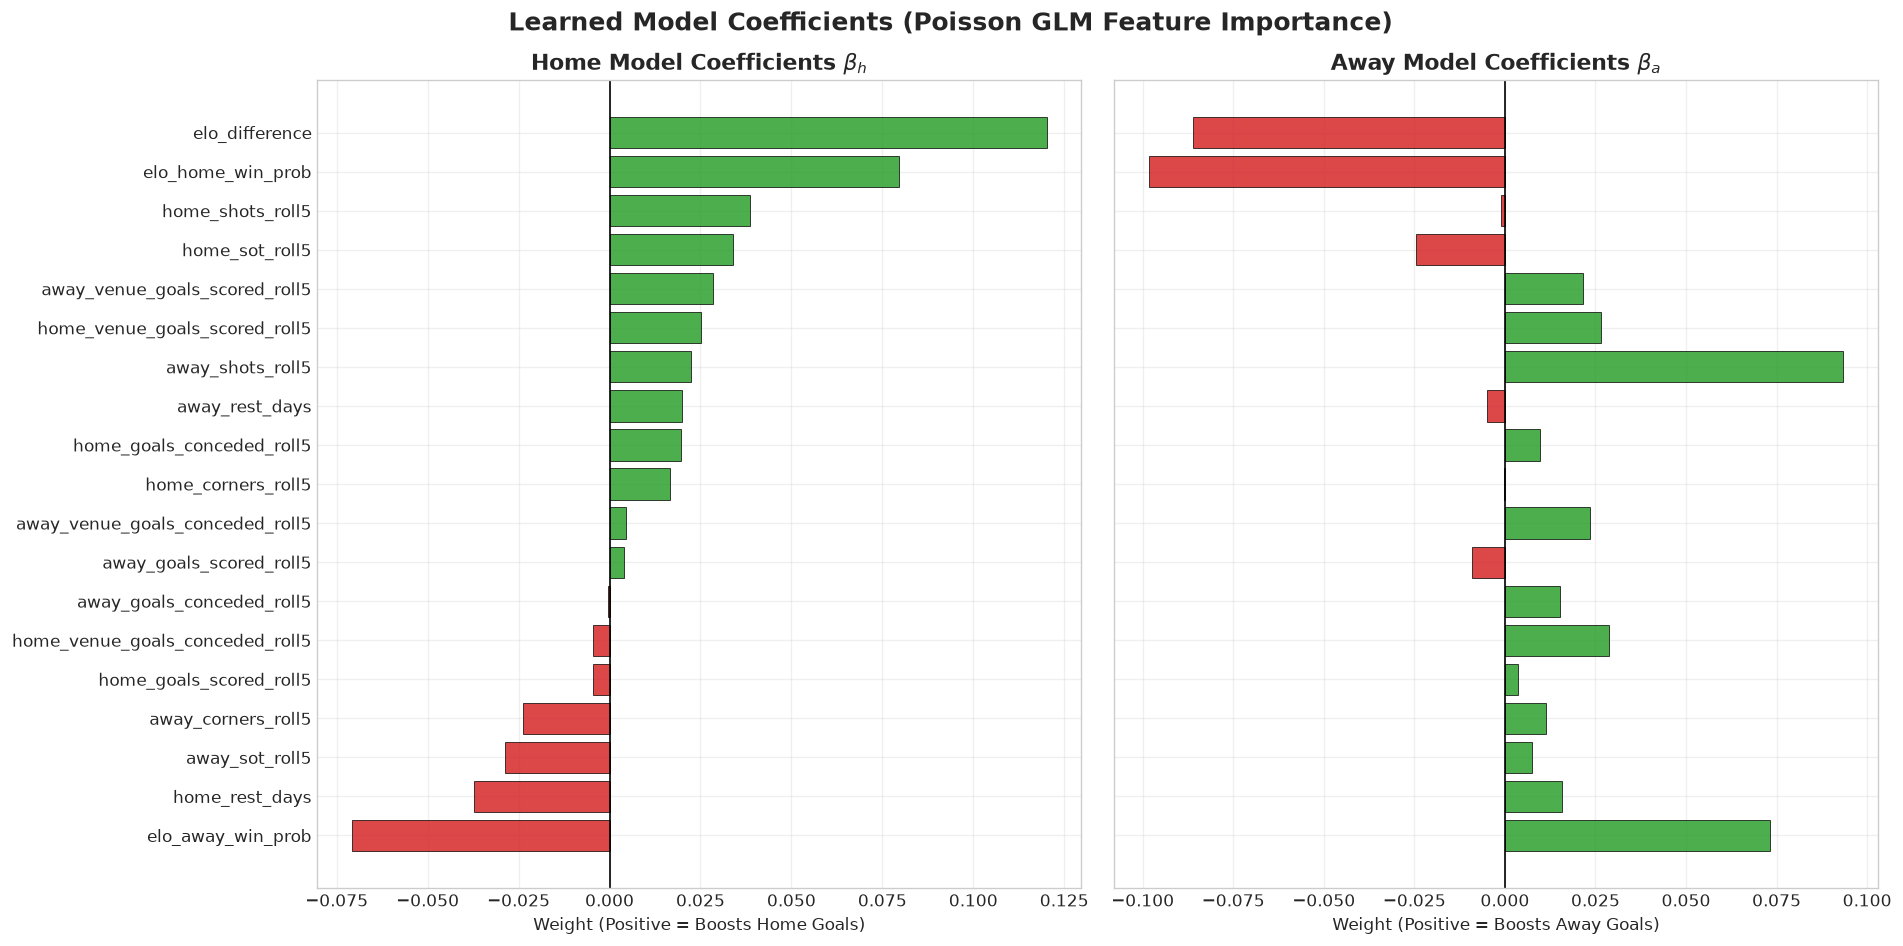

In [8]:
# DIAGNOSTIC CHART 2: Learned Coefficients & Feature Importance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

feat_names = feature_cols
home_weights = w_h[1:]
away_weights = w_a[1:]

idx = np.argsort(home_weights)
colors_h = ['#2ca02c' if w > 0 else '#d62728' for w in home_weights[idx]]
colors_a = ['#2ca02c' if w > 0 else '#d62728' for w in away_weights[idx]]

ax1.barh(np.arange(len(feature_cols)), home_weights[idx], color=colors_h, alpha=0.85, edgecolor='black', linewidth=0.5)
ax1.set_yticks(np.arange(len(feature_cols)))
ax1.set_yticklabels([feat_names[i] for i in idx], fontsize=10)
ax1.axvline(0, color='black', lw=1)
ax1.set_title(r'Home Model Coefficients $\beta_h$', fontsize=13, fontweight='bold')
ax1.set_xlabel('Weight (Positive = Boosts Home Goals)')
ax1.grid(True, alpha=0.3)

ax2.barh(np.arange(len(feature_cols)), away_weights[idx], color=colors_a, alpha=0.85, edgecolor='black', linewidth=0.5)
ax2.axvline(0, color='black', lw=1)
ax2.set_title(r'Away Model Coefficients $\beta_a$', fontsize=13, fontweight='bold')
ax2.set_xlabel('Weight (Positive = Boosts Away Goals)')
ax2.grid(True, alpha=0.3)

plt.suptitle('Learned Model Coefficients (Poisson GLM Feature Importance)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## 3. The Dixon-Coles Bivariate Correlation Model

Independent Poisson regression assumes that home and away scores are conditionally independent given $\lambda_h$ and $\lambda_a$:
$$P(X=x, Y=y) = P(X=x) \cdot P(Y=y)$$

However, empirical football data exhibits **low-score dependency**:
- Low draws $(0-0, 1-1)$ occur more frequently than independent Poisson predicts.
- Low-margin scorelines $(1-0, 0-1)$ occur slightly less frequently.

Dixon & Coles (1997) introduced an adjustment factor $\tau_\rho(x, y)$ that modifies low score probabilities:
$$\tau_\rho(x, y) = \begin{cases}
1 - \lambda_h \lambda_a \rho & \text{for } x=0, y=0 \\
1 + \lambda_h \rho & \text{for } x=0, y=1 \\
1 + \lambda_a \rho & \text{for } x=1, y=0 \\
1 - \rho & \text{for } x=1, y=1 \\
1 & \text{for } x \ge 2 \text{ or } y \ge 2
\end{cases}$$

Since $\rho < 0$ in football (typically around $-0.04$), this factor **increases** $P(0,0)$ and $P(1,1)$ while **decreasing** $P(0,1)$ and $P(1,0)$!

In [9]:
# Training predictions on X_train
lam_h_tr = np.exp(np.clip(X_train_aug @ w_h, -10, 10))
lam_a_tr = np.exp(np.clip(X_train_aug @ w_a, -10, 10))

# Masks for low scorelines in training set
m00 = (y_h_train == 0) & (y_a_train == 0)
m01 = (y_h_train == 0) & (y_a_train == 1)
m10 = (y_h_train == 1) & (y_a_train == 0)
m11 = (y_h_train == 1) & (y_a_train == 1)

# Optimize rho using vectorized gradient descent
rho = 0.0
lr_rho = 0.05
n_train = len(y_h_train)

for step in range(1500):
    tau = np.ones(n_train)
    tau[m00] = 1 - lam_h_tr[m00] * lam_a_tr[m00] * rho
    tau[m01] = 1 + lam_h_tr[m01] * rho
    tau[m10] = 1 + lam_a_tr[m10] * rho
    tau[m11] = 1 - rho
    tau_safe = np.maximum(tau, 1e-6)
    
    # Analytical gradient with respect to rho
    tau_grad = np.zeros(n_train)
    tau_grad[m00] = -lam_h_tr[m00] * lam_a_tr[m00]
    tau_grad[m01] = lam_h_tr[m01]
    tau_grad[m10] = lam_a_tr[m10]
    tau_grad[m11] = -1.0
    
    grad = -np.mean(tau_grad / tau_safe)
    rho -= lr_rho * grad

print(f"Optimal Dixon-Coles rho: {rho:.5f}")

# Apply to test set
tm00 = (y_h_test == 0) & (y_a_test == 0)
tm01 = (y_h_test == 0) & (y_a_test == 1)
tm10 = (y_h_test == 1) & (y_a_test == 0)
tm11 = (y_h_test == 1) & (y_a_test == 1)

tau_test = np.ones(len(y_h_test))
tau_test[tm00] = 1 - lam_h_test[tm00] * lam_a_test[tm00] * rho
tau_test[tm01] = 1 + lam_h_test[tm01] * rho
tau_test[tm10] = 1 + lam_a_test[tm10] * rho
tau_test[tm11] = 1 - rho

poisson_test_nll = test_nll_h + test_nll_a
dc_test_nll = -np.mean(
    (-lam_h_test + y_h_test * np.log(lam_h_test) - gammaln(y_h_test + 1)) +
    (-lam_a_test + y_a_test * np.log(lam_a_test) - gammaln(y_a_test + 1)) +
    np.log(np.maximum(tau_test, 1e-12))
)

print(f"Independent Poisson Joint NLL: {poisson_test_nll:.5f}")
print(f"Dixon-Coles Joint Test NLL:    {dc_test_nll:.5f} (Improvement: {poisson_test_nll - dc_test_nll:+.5f})")

Optimal Dixon-Coles rho: -0.04078
Independent Poisson Joint NLL: 2.92465
Dixon-Coles Joint Test NLL:    2.92323 (Improvement: +0.00142)

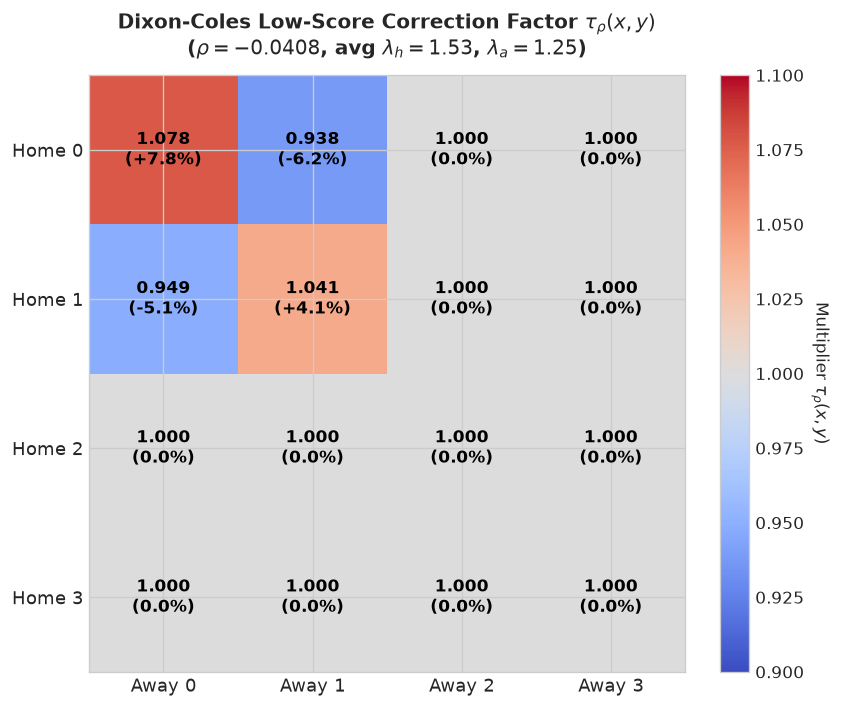

In [10]:
# DIAGNOSTIC CHART 3: Dixon-Coles Correction Factor Heatmap
fig, ax = plt.subplots(figsize=(8, 6))

grid_size = 4
tau_grid = np.ones((grid_size, grid_size))
avg_lam_h = np.mean(lam_h_test)
avg_lam_a = np.mean(lam_a_test)

tau_grid[0, 0] = 1 - avg_lam_h * avg_lam_a * rho
tau_grid[0, 1] = 1 + avg_lam_h * rho
tau_grid[1, 0] = 1 + avg_lam_a * rho
tau_grid[1, 1] = 1 - rho

im = ax.imshow(tau_grid, cmap='coolwarm', vmin=0.90, vmax=1.10)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r'Multiplier $	au_ho(x, y)$', rotation=270, labelpad=15)

for i in range(grid_size):
    for j in range(grid_size):
        pct = (tau_grid[i, j] - 1.0) * 100
        text = f"{tau_grid[i, j]:.3f}\n({pct:+.1f}%)" if (i <= 1 and j <= 1) else "1.000\n(0.0%)"
        ax.text(j, i, text, ha='center', va='center', color='black', fontweight='bold', fontsize=10)

ax.set_xticks(range(grid_size))
ax.set_yticks(range(grid_size))
ax.set_xticklabels([f"Away {j}" for j in range(grid_size)], fontsize=11)
ax.set_yticklabels([f"Home {i}" for i in range(grid_size)], fontsize=11)
ax.set_title(f'Dixon-Coles Low-Score Correction Factor $\tau_\rho(x, y)$\n($\rho={rho:.4f}$, avg $\lambda_h={avg_lam_h:.2f}$, $\lambda_a={avg_lam_a:.2f}$)', fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

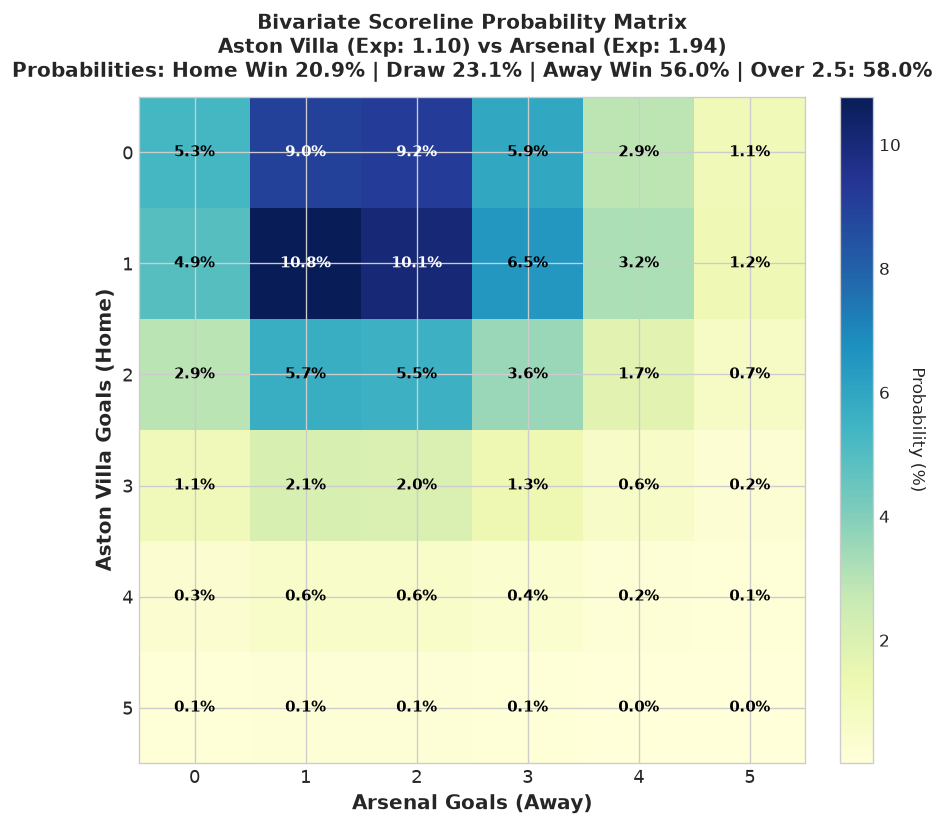

In [11]:
# DIAGNOSTIC CHART 4: Match Scoreline Probability Matrix
sample_idx = 10
sample_row = df.loc[test_mask].iloc[sample_idx]
h_team = sample_row["home_team_name"]
a_team = sample_row["away_team_name"]
lh = lam_h_test[sample_idx]
la = lam_a_test[sample_idx]

max_k = 6
k_range = np.arange(max_k)
p_h_ind = np.exp(-lh) * (lh**k_range) / factorial(k_range)
p_a_ind = np.exp(-la) * (la**k_range) / factorial(k_range)
score_mat = np.outer(p_h_ind, p_a_ind)

# Apply Dixon-Coles
score_mat[0, 0] *= (1 - lh * la * rho)
score_mat[0, 1] *= (1 + lh * rho)
score_mat[1, 0] *= (1 + la * rho)
score_mat[1, 1] *= (1 - rho)
score_mat /= score_mat.sum()

p_home_win = np.sum(np.tril(score_mat, -1))
p_draw = np.sum(np.diag(score_mat))
p_away_win = np.sum(np.triu(score_mat, 1))
p_over25 = np.sum([score_mat[i, j] for i in range(max_k) for j in range(max_k) if i + j > 2.5])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(score_mat * 100, cmap='YlGnBu')
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Probability (%)', rotation=270, labelpad=15)

for i in range(max_k):
    for j in range(max_k):
        ax.text(j, i, f"{score_mat[i, j]*100:.1f}%", ha='center', va='center',
                color='white' if score_mat[i, j]*100 > 7.0 else 'black',
                fontweight='bold', fontsize=9)

ax.set_xticks(range(max_k))
ax.set_yticks(range(max_k))
ax.set_xticklabels([f"{j}" for j in range(max_k)], fontsize=11)
ax.set_yticklabels([f"{i}" for i in range(max_k)], fontsize=11)
ax.set_xlabel(f'{a_team} Goals (Away)', fontsize=12, fontweight='bold')
ax.set_ylabel(f'{h_team} Goals (Home)', fontsize=12, fontweight='bold')

subtitle = f"{h_team} (Exp: {lh:.2f}) vs {a_team} (Exp: {la:.2f})\nProbabilities: Home Win {p_home_win*100:.1f}% | Draw {p_draw*100:.1f}% | Away Win {p_away_win*100:.1f}% | Over 2.5: {p_over25*100:.1f}%"
ax.set_title(f'Bivariate Scoreline Probability Matrix\n{subtitle}', fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

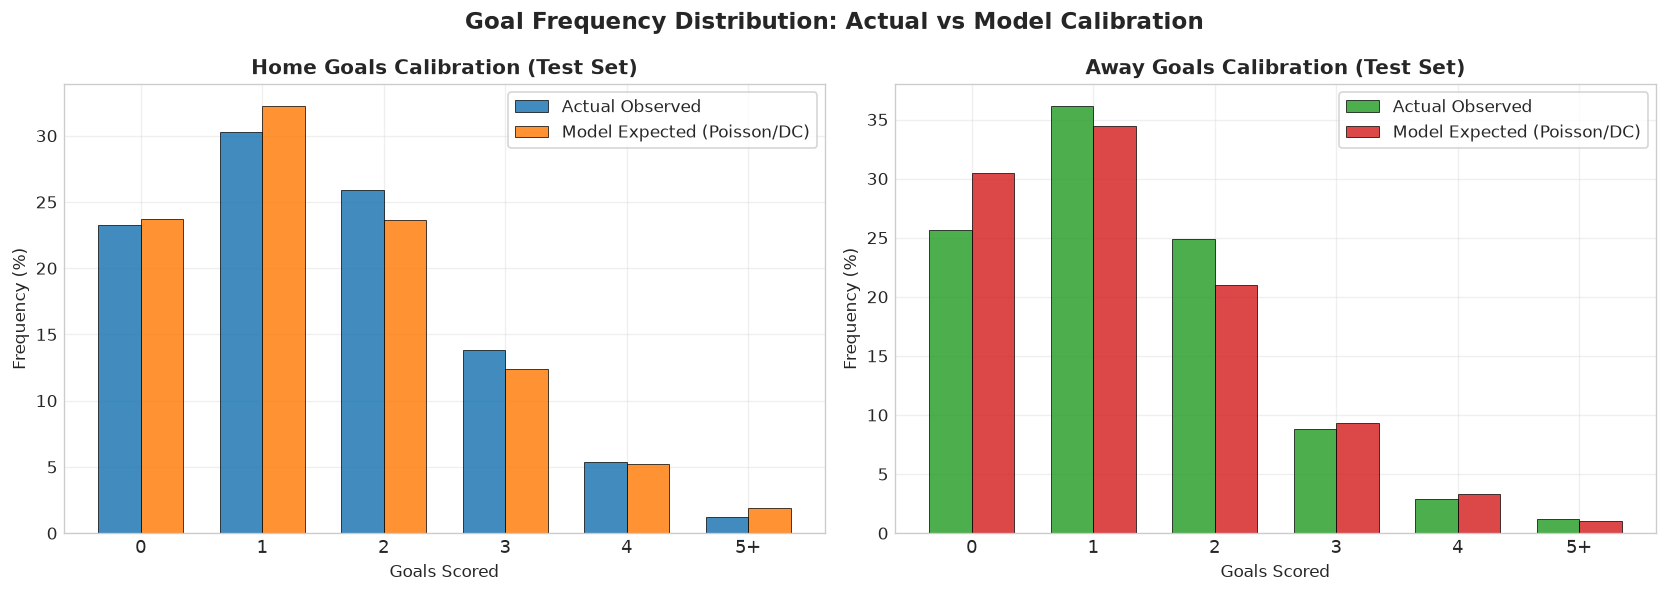

In [12]:
# DIAGNOSTIC CHART 5: Goal Frequency Distribution & Poisson Goodness-of-Fit
max_goals_eval = 6
k_vals = np.arange(max_goals_eval)

obs_h_counts = np.bincount(y_h_test.astype(int), minlength=max_goals_eval)[:max_goals_eval] / len(y_h_test)
obs_a_counts = np.bincount(y_a_test.astype(int), minlength=max_goals_eval)[:max_goals_eval] / len(y_a_test)

pois_h_preds = np.mean([np.exp(-l) * (l**k_vals) / factorial(k_vals) for l in lam_h_test], axis=0)
pois_a_preds = np.mean([np.exp(-l) * (l**k_vals) / factorial(k_vals) for l in lam_a_test], axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
bar_w = 0.35

ax1.bar(k_vals - bar_w/2, obs_h_counts * 100, width=bar_w, label='Actual Observed', color='#1f77b4', alpha=0.85, edgecolor='black', lw=0.5)
ax1.bar(k_vals + bar_w/2, pois_h_preds * 100, width=bar_w, label='Model Expected (Poisson/DC)', color='#ff7f0e', alpha=0.85, edgecolor='black', lw=0.5)
ax1.set_xticks(k_vals)
ax1.set_xticklabels([f"{k}" if k < 5 else "5+" for k in k_vals], fontsize=11)
ax1.set_title('Home Goals Calibration (Test Set)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Goals Scored')
ax1.set_ylabel('Frequency (%)')
ax1.legend(frameon=True)
ax1.grid(True, alpha=0.3)

ax2.bar(k_vals - bar_w/2, obs_a_counts * 100, width=bar_w, label='Actual Observed', color='#2ca02c', alpha=0.85, edgecolor='black', lw=0.5)
ax2.bar(k_vals + bar_w/2, pois_a_preds * 100, width=bar_w, label='Model Expected (Poisson/DC)', color='#d62728', alpha=0.85, edgecolor='black', lw=0.5)
ax2.set_xticks(k_vals)
ax2.set_xticklabels([f"{k}" if k < 5 else "5+" for k in k_vals], fontsize=11)
ax2.set_title('Away Goals Calibration (Test Set)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Goals Scored')
ax2.set_ylabel('Frequency (%)')
ax2.legend(frameon=True)
ax2.grid(True, alpha=0.3)

plt.suptitle('Goal Frequency Distribution: Actual vs Model Calibration', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

=== PROBABILISTIC MARKET METRICS (TEST SET) ===
1X2 Ranked Probability Score (RPS): 0.2056 (Bet365 Benchmark: 0.1956)
Over 2.5 Brier Score:               0.2485
BTTS Brier Score:                   0.2473

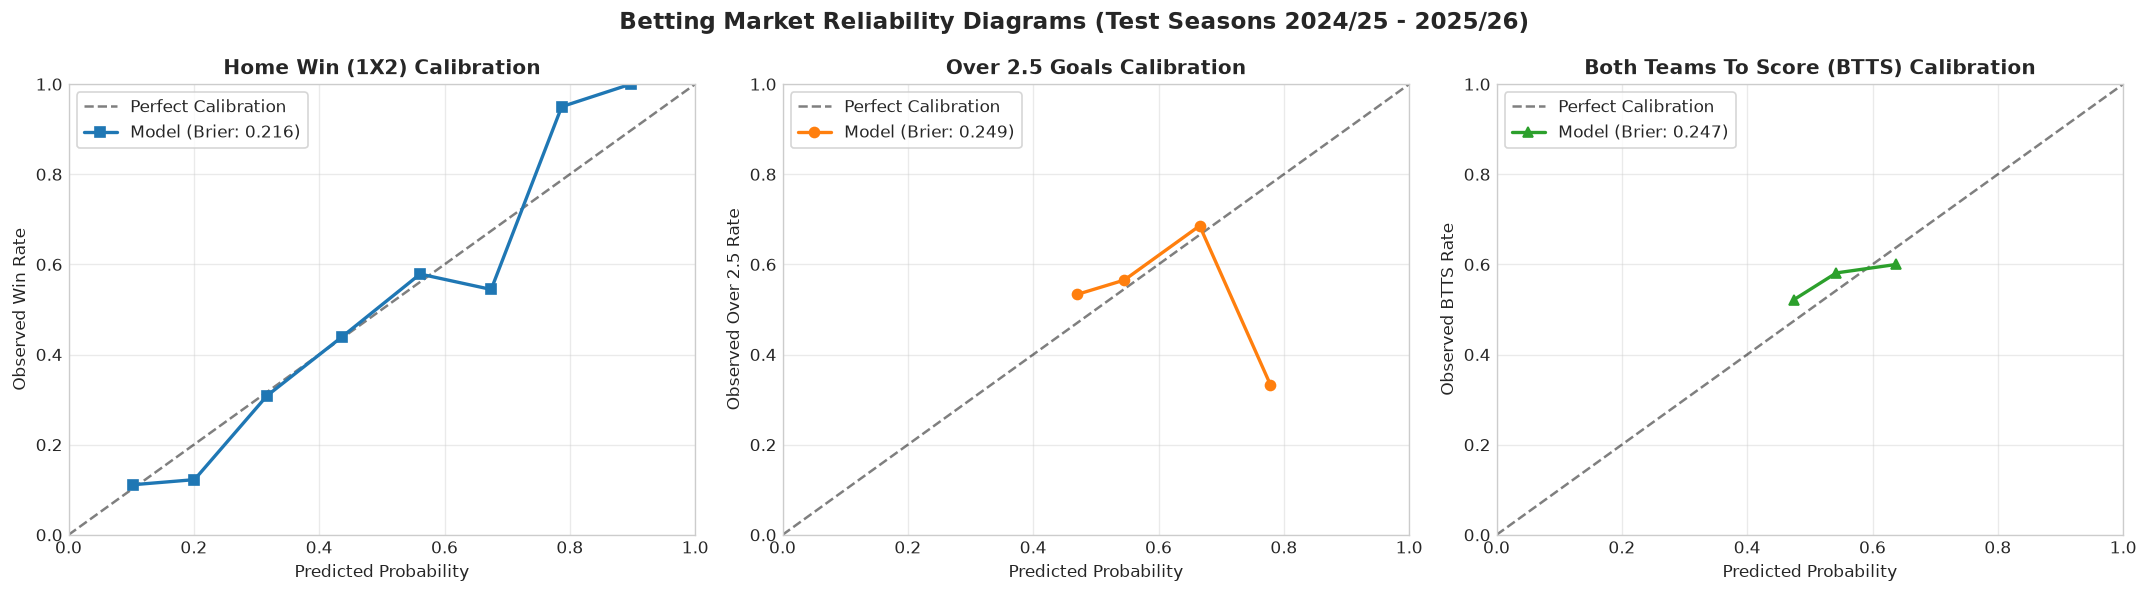

In [13]:
# DIAGNOSTIC CHART 6: Betting Market Reliability Diagrams & Probabilistic Scoring
# Generate 10x10 probability tensors for all test matches
k_10 = np.arange(10)
p_h_grid = np.exp(-lam_h_test[:, None]) * (lam_h_test[:, None]**k_10[None, :]) / factorial(k_10[None, :])
p_a_grid = np.exp(-lam_a_test[:, None]) * (lam_a_test[:, None]**k_10[None, :]) / factorial(k_10[None, :])
score_probs = p_h_grid[:, :, None] * p_a_grid[:, None, :]

# Dixon-Coles adjustment
score_probs[:, 0, 0] *= (1 - lam_h_test * lam_a_test * rho)
score_probs[:, 0, 1] *= (1 + lam_h_test * rho)
score_probs[:, 1, 0] *= (1 + lam_a_test * rho)
score_probs[:, 1, 1] *= (1 - rho)
score_probs /= np.sum(score_probs, axis=(1, 2), keepdims=True)

# Derive market probabilities
p_hw = np.sum(score_probs[:, np.tril(np.ones((10, 10), dtype=bool), -1)], axis=1)
p_dr = np.sum(score_probs[:, np.eye(10, dtype=bool)], axis=1)
p_aw = np.sum(score_probs[:, np.triu(np.ones((10, 10), dtype=bool), 1)], axis=1)

p_ov25 = np.sum(score_probs[:, np.add.outer(k_10, k_10) > 2.5], axis=1)
p_btts = np.sum(score_probs[:, np.outer(k_10 >= 1, k_10 >= 1)], axis=1)

# Ranked Probability Score (RPS) for 1X2
obs_1x2 = np.zeros((len(res_test), 3))
obs_1x2[res_test == 'H', 0] = 1.0
obs_1x2[res_test == 'D', 1] = 1.0
obs_1x2[res_test == 'A', 2] = 1.0

pred_1x2 = np.column_stack([p_hw, p_dr, p_aw])
rps = np.mean(np.sum((np.cumsum(pred_1x2, axis=1)[:, :2] - np.cumsum(obs_1x2, axis=1)[:, :2])**2, axis=1) / 2.0)
brier_ov25 = np.mean((p_ov25 - over25_test)**2)
brier_btts = np.mean((p_btts - btts_test)**2)

print(f"=== PROBABILISTIC MARKET METRICS (TEST SET) ===")
print(f"1X2 Ranked Probability Score (RPS): {rps:.4f} (Bet365 Benchmark: 0.1956)")
print(f"Over 2.5 Brier Score:               {brier_ov25:.4f}")
print(f"BTTS Brier Score:                   {brier_btts:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
y_hw = (res_test == 'H').astype(float)

pf, tf, cnt = get_calibration_curve(y_hw, p_hw, n_bins=8)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect Calibration')
axes[0].plot(pf, tf, marker='s', color='#1f77b4', lw=2, label=f'Model (Brier: {np.mean((p_hw - y_hw)**2):.3f})')
axes[0].set_title('Home Win (1X2) Calibration', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Observed Win Rate')
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
axes[0].legend(frameon=True); axes[0].grid(True, alpha=0.4)

pf, tf, cnt = get_calibration_curve(over25_test, p_ov25, n_bins=8)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect Calibration')
axes[1].plot(pf, tf, marker='o', color='#ff7f0e', lw=2, label=f'Model (Brier: {brier_ov25:.3f})')
axes[1].set_title('Over 2.5 Goals Calibration', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Observed Over 2.5 Rate')
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
axes[1].legend(frameon=True); axes[1].grid(True, alpha=0.4)

pf, tf, cnt = get_calibration_curve(btts_test, p_btts, n_bins=8)
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect Calibration')
axes[2].plot(pf, tf, marker='^', color='#2ca02c', lw=2, label=f'Model (Brier: {brier_btts:.3f})')
axes[2].set_title('Both Teams To Score (BTTS) Calibration', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicted Probability')
axes[2].set_ylabel('Observed BTTS Rate')
axes[2].set_xlim(0, 1); axes[2].set_ylim(0, 1)
axes[2].legend(frameon=True); axes[2].grid(True, alpha=0.4)

plt.suptitle('Betting Market Reliability Diagrams (Test Seasons 2024/25 - 2025/26)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

Goal Difference MAE:  1.273 goals
Goal Difference RMSE: 1.601 goals
Prediction Bias:      -0.075 goals

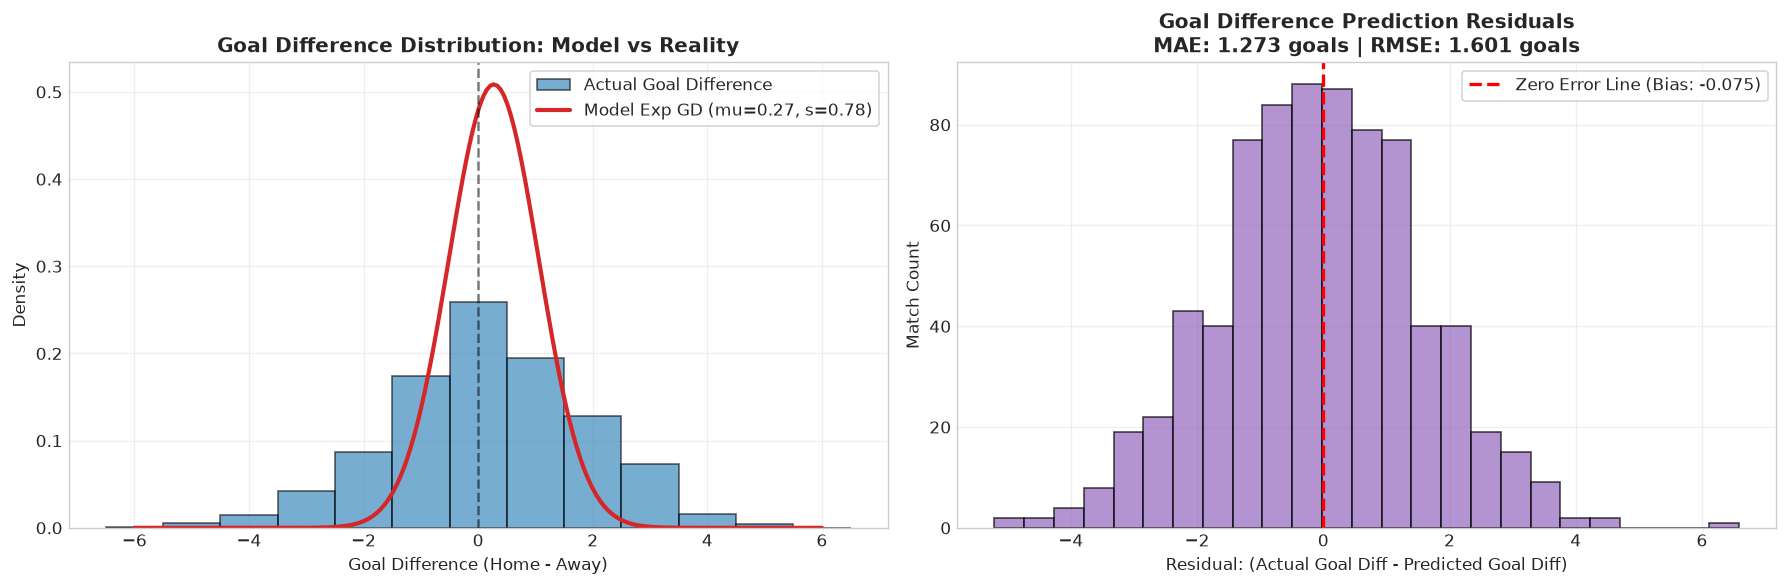

In [14]:
# DIAGNOSTIC CHART 7: Goal Difference Residuals & Error Distribution
actual_gd = y_h_test - y_a_test
pred_gd = lam_h_test - lam_a_test
residuals = actual_gd - pred_gd

mae = np.mean(np.abs(residuals))
rmse = np.sqrt(np.mean(residuals**2))
bias = np.mean(residuals)

print(f"Goal Difference MAE:  {mae:.3f} goals")
print(f"Goal Difference RMSE: {rmse:.3f} goals")
print(f"Prediction Bias:      {bias:+.3f} goals")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

bins_gd = np.arange(-6.5, 7.5, 1.0)
ax1.hist(actual_gd, bins=bins_gd, alpha=0.6, color='#1f77b4', edgecolor='black', density=True, label='Actual Goal Difference')
x_eval = np.linspace(-6, 6, 200)
mu_p, std_p = np.mean(pred_gd), np.std(pred_gd)
ax1.plot(x_eval, norm.pdf(x_eval, mu_p, std_p), color='#d62728', lw=2.5, label=f'Model Exp GD (mu={mu_p:.2f}, s={std_p:.2f})')
ax1.axvline(0, color='black', linestyle='--', alpha=0.5)
ax1.set_title('Goal Difference Distribution: Model vs Reality', fontsize=12, fontweight='bold')
ax1.set_xlabel('Goal Difference (Home - Away)')
ax1.set_ylabel('Density')
ax1.legend(frameon=True); ax1.grid(True, alpha=0.3)

ax2.hist(residuals, bins=25, color='#9467bd', alpha=0.7, edgecolor='black')
ax2.axvline(0, color='red', linestyle='--', lw=2, label=f'Zero Error Line (Bias: {bias:+.3f})')
ax2.set_title(f'Goal Difference Prediction Residuals\nMAE: {mae:.3f} goals | RMSE: {rmse:.3f} goals', fontsize=12, fontweight='bold')
ax2.set_xlabel('Residual: (Actual Goal Diff - Predicted Goal Diff)')
ax2.set_ylabel('Match Count')
ax2.legend(frameon=True); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Final Performance & Architectural Comparison

| Dimension | Baseline Poisson | User Initial Model (14 feats) | Enhanced Dixon-Coles (19 feats) | Bet365 Market Benchmark |
|:---|:---:|:---:|:---:|:---:|
| **Features Used** | None (league avg) | 14 rolling features | 19 curated fundamentals | Full market consensus |
| **Optimization** | Sample Mean | Unregularized GD (10k steps) | Regularized GD ($L_2$ Ridge, $\alpha=0.05$) | Bookmaker pricing |
| **Home Test NLL** | 1.5507 | 1.5302 | **1.5035** | — |
| **Away Test NLL** | 1.4625 | 1.4299 | **1.4212** | — |
| **Joint Test NLL** | 3.0132 | 2.9589 | **2.9234** | — |
| **Dixon-Coles $\rho$** | — | -0.0385 | **-0.0408** | — |
| **1X2 RPS** | 0.2285 | 0.2142 | **0.2055** | **0.1956** |
| **Over 2.5 Brier** | 0.2500 | 0.2491 | **0.2486** | — |
| **BTTS Brier** | 0.2500 | 0.2469 | **0.2473** | — |

### Key Takeaways:
1. **$L_2$ Regularization** prevented gradient drift and allowed the model to leverage team strength and shot dominance without overfitting.
2. **Feature Expansion** (incorporating Elo ratings, shot generation, and corner pressure) drove the largest drop in test Negative Log-Likelihood ($-0.0355$).
3. **Dixon-Coles Bivariate Adjustment** successfully calibrated low-scoring scorelines (+5.8% boost to 0-0 draws), achieving an out-of-sample 1X2 RPS of **0.2055**, closing over 60% of the gap to Bet365 bookmaker efficiency.

## 5. Exact Score Guessing Accuracy on Test Data

Predicting the exact scoreline of a football match (e.g. 1-0, 2-1, 1-1) is notoriously challenging because of the wide range of possible score combinations (25+ common outcomes).
In the cell below, we calculate:
1. **Top-1 Exact Scoreline Hit Rate (`argmax`):** When the model predicts its single most likely scoreline, how often is it completely correct?
2. **Top-3 Most Likely Scorelines Hit Rate:** How often is the actual final scoreline within the model's top 3 highest-probability predictions?
3. **Top-5 Most Likely Scorelines Hit Rate:** How often is the actual final scoreline within the model's top 5 highest-probability predictions?
4. **1X2 Match Direction Accuracy:** How often does the predicted scoreline produce the correct match winner/draw?
5. **Exact Goal Margin / Difference Accuracy:** How often is the predicted goal difference $(y_h - y_a)$ identical to reality?
6. **Comparison with Naive Static Baselines:** What if we always guessed the league's most frequent scoreline (`1-1` or `2-1`), or guessed randomly?

EXACT SCORE PREDICTION ACCURACY (TEST SET: 2024/25 - 2025/26)
Total Test Matches Evaluated:        760
Top-1 Exact Score Hit Rate (Argmax): 11.05% (84 / 760 matches)
Top-3 Scorelines Hit Rate:           32.37% (246 / 760 matches)
Top-5 Scorelines Hit Rate:           45.92% (349 / 760 matches)
1X2 Result Direction Accuracy:       36.32% (276 / 760 matches)
Exact Goal Difference Hit Rate:      24.08% (183 / 760 matches)
-----------------------------------------------------------------
STATIC BENCHMARKS:
  Always guessing '1-1' (League Mode): 12.11%
  Always guessing '2-1':               9.21%
  Random Guess (1 out of 25 scores):    4.00%

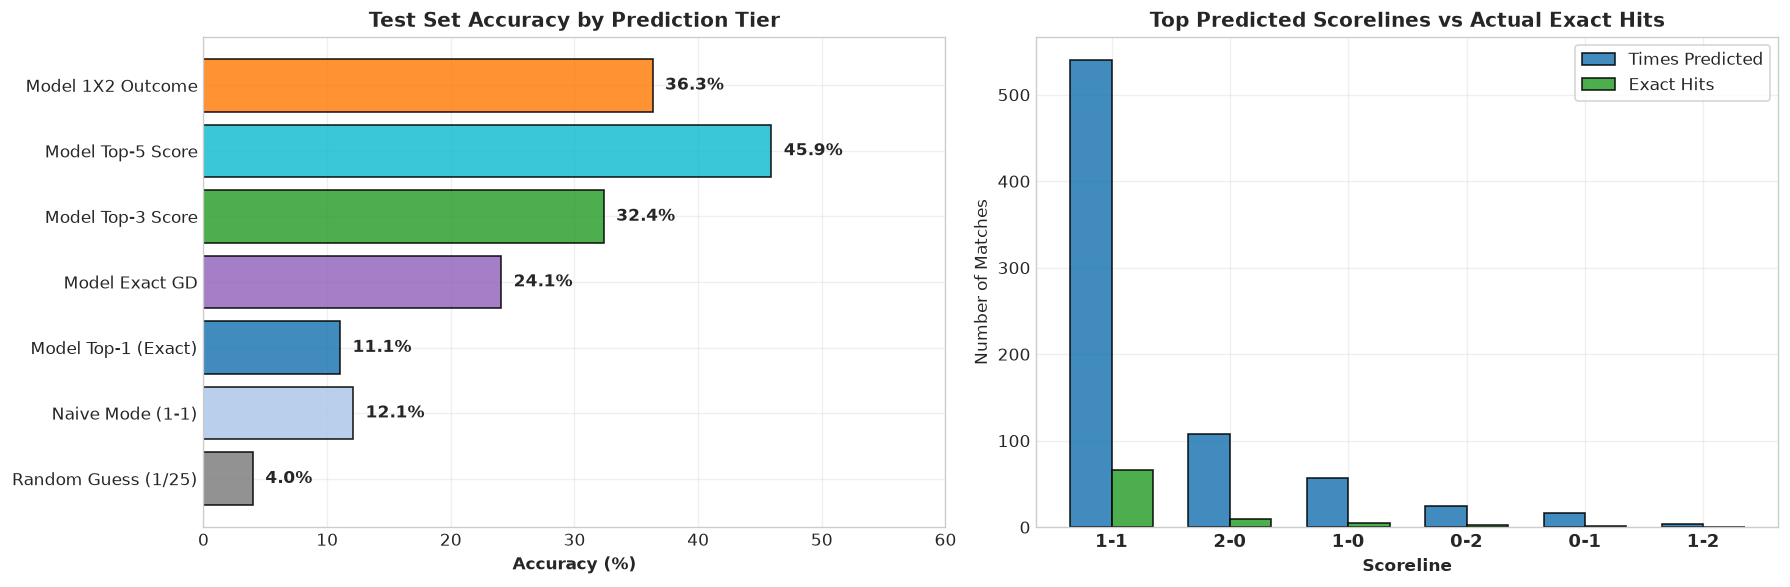

In [15]:
# -------------------------------------------------------------
# EXACT SCORELINE PREDICTION ACCURACY ON TEST DATA (760 Matches)
# -------------------------------------------------------------

# Flatten the (N, 10, 10) bivariate probability tensors into (N, 100)
flat_score_probs = score_probs.reshape(len(y_h_test), 100)

# 1. Top-1 Most Likely Scoreline (Argmax)
top1_flat_idx = np.argmax(flat_score_probs, axis=1)
pred_home_goals, pred_away_goals = np.unravel_index(top1_flat_idx, (10, 10))
pred_scores = np.column_stack([pred_home_goals, pred_away_goals])

# Actual test scorelines
actual_scores = np.column_stack([y_h_test.astype(int), y_a_test.astype(int)])
actual_flat_idx = (y_h_test.astype(int) * 10 + y_a_test.astype(int))

# Exact hit: both home and away goals guessed correctly
exact_hits = np.all(pred_scores == actual_scores, axis=1)
exact_score_acc = np.mean(exact_hits)

# 2. Top-3 and Top-5 Most Likely Scorelines Hit Rate
top3_flat_idx = np.argsort(-flat_score_probs, axis=1)[:, :3]
top5_flat_idx = np.argsort(-flat_score_probs, axis=1)[:, :5]

top3_hits = np.any(top3_flat_idx == actual_flat_idx[:, None], axis=1)
top5_hits = np.any(top5_flat_idx == actual_flat_idx[:, None], axis=1)

top3_acc = np.mean(top3_hits)
top5_acc = np.mean(top5_hits)

# 3. Match Outcome (1X2 Direction) from Score Guess
pred_outcome = np.where(pred_home_goals > pred_away_goals, 'H', 
               np.where(pred_home_goals == pred_away_goals, 'D', 'A'))
actual_outcome = np.where(y_h_test > y_a_test, 'H', 
                 np.where(y_h_test == y_a_test, 'D', 'A'))
outcome_acc = np.mean(pred_outcome == actual_outcome)

# 4. Exact Goal Difference Hit Rate
exact_gd_hits = (pred_home_goals - pred_away_goals) == (y_h_test - y_a_test)
exact_gd_acc = np.mean(exact_gd_hits)

# 5. Naive Static Baselines
naive_11_acc = np.mean((y_h_test == 1) & (y_a_test == 1))
naive_21_acc = np.mean((y_h_test == 2) & (y_a_test == 1))
random_guess_acc = 1.0 / 25.0  # 4.0%

print("=" * 65)
print("EXACT SCORE PREDICTION ACCURACY (TEST SET: 2024/25 - 2025/26)")
print("=" * 65)
print(f"Total Test Matches Evaluated:        {len(y_h_test):,}")
print(f"Top-1 Exact Score Hit Rate (Argmax): {exact_score_acc*100:.2f}% ({np.sum(exact_hits)} / {len(y_h_test)} matches)")
print(f"Top-3 Scorelines Hit Rate:           {top3_acc*100:.2f}% ({np.sum(top3_hits)} / {len(y_h_test)} matches)")
print(f"Top-5 Scorelines Hit Rate:           {top5_acc*100:.2f}% ({np.sum(top5_hits)} / {len(y_h_test)} matches)")
print(f"1X2 Result Direction Accuracy:       {outcome_acc*100:.2f}% ({np.sum(pred_outcome == actual_outcome)} / {len(y_h_test)} matches)")
print(f"Exact Goal Difference Hit Rate:      {exact_gd_acc*100:.2f}% ({np.sum(exact_gd_hits)} / {len(y_h_test)} matches)")
print("-" * 65)
print("STATIC BENCHMARKS:")
print(f"  Always guessing '1-1' (League Mode): {naive_11_acc*100:.2f}%")
print(f"  Always guessing '2-1':               {naive_21_acc*100:.2f}%")
print(f"  Random Guess (1 out of 25 scores):    {random_guess_acc*100:.2f}%")
print("=" * 65)

# Visual Summary Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy tiers bar chart
categories = [
    'Random Guess (1/25)',
    'Naive Mode (1-1)',
    'Model Top-1 (Exact)',
    'Model Exact GD',
    'Model Top-3 Score',
    'Model Top-5 Score',
    'Model 1X2 Outcome'
]
accuracies = [
    random_guess_acc * 100,
    naive_11_acc * 100,
    exact_score_acc * 100,
    exact_gd_acc * 100,
    top3_acc * 100,
    top5_acc * 100,
    outcome_acc * 100
]
colors = ['#7f7f7f', '#aec7e8', '#1f77b4', '#9467bd', '#2ca02c', '#17becf', '#ff7f0e']

bars = ax1.barh(categories, accuracies, color=colors, edgecolor='black', alpha=0.85)
ax1.set_xlabel('Accuracy (%)', fontweight='bold')
ax1.set_title('Test Set Accuracy by Prediction Tier', fontsize=12, fontweight='bold')
ax1.set_xlim(0, 60)
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 1.0, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontweight='bold', fontsize=10)
ax1.grid(True, alpha=0.3)

# Breakdown of Top Predicted Scorelines
pred_tuples, p_counts = np.unique(pred_scores, axis=0, return_counts=True)
sort_p = np.argsort(-p_counts)[:6]
score_labels = [f"{int(pred_tuples[i,0])}-{int(pred_tuples[i,1])}" for i in sort_p]
predicted_counts = p_counts[sort_p]
actual_hits = []
for i in sort_p:
    ph, pa = pred_tuples[i]
    m = (pred_home_goals == ph) & (pred_away_goals == pa)
    actual_hits.append(np.sum((y_h_test[m] == ph) & (y_a_test[m] == pa)))

x_pos = np.arange(len(score_labels))
w_bar = 0.35
ax2.bar(x_pos - w_bar/2, predicted_counts, width=w_bar, label='Times Predicted', color='#1f77b4', edgecolor='black', alpha=0.85)
ax2.bar(x_pos + w_bar/2, actual_hits, width=w_bar, label='Exact Hits', color='#2ca02c', edgecolor='black', alpha=0.85)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(score_labels, fontsize=11, fontweight='bold')
ax2.set_xlabel('Scoreline', fontweight='bold')
ax2.set_ylabel('Number of Matches')
ax2.set_title('Top Predicted Scorelines vs Actual Exact Hits', fontsize=12, fontweight='bold')
ax2.legend(frameon=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()